# Higgs Effective Field Theory (HEFT) Study: Evaluating the Density Network
> Created: Nov 05, 2026 Pushpa Bhat (Fermilab), Nicola de Filippis (Bari),<br> Kurtis Johnson,  Harrison B. Prosper, Ryne Starnes (FSU)<br>\n> Updated: Nov 05, 2026 HBP: Runs with the smoothness penalty; smoothness of the coefficient functions.<br>

## Introduction

The density network `HEFTDensity` (`dihiggs/heftnet.py`) models $d\sigma/dm_{hh} = \sum_i C_i(\theta)\,a_i(m_{hh})$ and is compared with POWHEG through its **bin integrals**. Its runs are made by `heft_train.ipynb` (`MODEL = 'density'`, L1 loss) and `heft_finetune.ipynb` (Huber loss of the pulls, Poisson variances from the model). This notebook evaluates them exactly as the smooth spline model was evaluated for the paper (`docs/dihiggs_model.pdf`), on the 1,000 test spectra, which played no part in training:

1. **Accuracy**: the likelihood-ratio statistic $-2\ln\lambda$, $\lambda = \mathrm{Poisson}(n;\mu)/\mathrm{Poisson}(n;n)$, with $n$ the exact POWHEG count and $\mu$ the prediction in events. For a correct model it follows $\chi^2_1$, mean 1.
2. **Calibration**: pulls with a model-error term $\delta = \varepsilon(m)\sum_i|C_iA_i|$, whose coefficient $\varepsilon(m)$ is determined, for each model, on the quick-test rows of the training file (never used in training).
3. **The density itself**: against the smooth model on a 0.5 GeV grid, between bin centres, and the 23 coefficient functions.
4. **Below the fitted range**: the unused POWHEG bin 240–255 GeV.

The plan is `docs/density/density_eval_plan.pdf`; the results are written up in `docs/density/density_results.pdf`. Everything runs on a laptop CPU in a few minutes.

**Why not the fine-tune notebook's $\chi^2$?** That is Neyman's $\chi^2$, $(n-\mu)^2/n$ with $n$ estimated through $N_\text{eff}$. Using the observed count as the variance favours predictions that are biased low, so it penalises a model fitted with its own Poisson variances, as the density networks are.

In [1]:
import os, sys

# the standard modules for arrays, tables and plots
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# pytorch, for the density networks
import torch

# root finding, for the model-error coefficient
from scipy.optimize import brentq

# module for shell utilities
import shutil

# update fonts
plt.rcParams.update({
  "text.usetex": shutil.which('latex') is not None,
  "font.family": "serif",
  "font.size": 11,
  "xtick.direction": "in", "ytick.direction": "in", "xtick.top": True, "ytick.right": True
})

## Switches

| switch | meaning |
| :--- | :--- |
| `RUNS` | the density-network run folders (in `runs/`) to evaluate |
| `FEATURED` | the run shown in the figures |
| `SPREAD_RUNS` | the runs whose spread is shown between bin centres |
| `FIGDIR` | where the figures are written |

In [2]:
# ------------------------------------------------------------------
# Switches
# ------------------------------------------------------------------
RUNS     = ['DENS_L1_SiLU_thr',
            'FTD_SiLU_huber_d1_pearson',
            'FTD_SiLU_huber_d2_pearson',
            'FTD_SiLU_huber_d3_pearson',
            'FTD_SiLU_chi2_pearson',
            'FTD_SiLU_huber_d2_pearson_curv1e-06',
            'FTD_SiLU_huber_d2_pearson_curv1e-05',
            'FTD_SiLU_huber_d2_pearson_curv0.0001']
FEATURED = 'FTD_SiLU_huber_d2_pearson_curv1e-06'
# the runs whose spread is shown between bin centres (the four unpenalised fine-tunes)
SPREAD_RUNS = ['FTD_SiLU_huber_d1_pearson', 'FTD_SiLU_huber_d2_pearson',
               'FTD_SiLU_huber_d3_pearson', 'FTD_SiLU_chi2_pearson']
FIGDIR   = '../docs/density'
RUNS = [r for r in RUNS if os.path.exists(f'runs/{r}/dihiggs_params.pth')]   # skip runs not yet made

# short labels for tables and legends
LABEL = {'DENS_L1_SiLU_thr': 'density, L1 (start)',
         'FTD_SiLU_huber_d1_pearson': r'density, Huber $\delta=1$',
         'FTD_SiLU_huber_d2_pearson': r'density, Huber $\delta=2$',
         'FTD_SiLU_huber_d3_pearson': r'density, Huber $\delta=3$',
         'FTD_SiLU_chi2_pearson': r'density, $\chi^2$',
         'FTD_SiLU_huber_d2_pearson_curv1e-06': r'density, $\delta=2$, $\lambda=10^{-6}$',
         'FTD_SiLU_huber_d2_pearson_curv1e-05': r'density, $\delta=2$, $\lambda=10^{-5}$',
         'FTD_SiLU_huber_d2_pearson_curv0.0001': r'density, $\delta=2$, $\lambda=10^{-4}$'}
os.makedirs(FIGDIR, exist_ok=True)

## The shared code and the reference models

`docs/paper/smooth_common.py`, shared with the paper figures, provides the 1,000 test spectra with their exact counts (`T`, `qt`, the counts `n`), the smooth model's predictions (`f`, its fit variance `v`, the sum of the magnitudes of its terms `S`, its model-error coefficient `eps`), the likelihood-ratio statistic `deviance`, and helpers for the training and quick-test rows, the old network ensemble and the density networks. Setting `__file__` first tells it where it lives, so that it finds the repository and keeps its cache in `docs/paper`.

In [3]:
__file__ = os.path.abspath('../docs/paper/smooth_common.py')
exec(open(__file__).read())

smooth  = SmoothHEFT.load(MODEL_FILE)
theta   = D['th']                       # [1000, 5] HEFT points of the test spectra
C_test  = D['C']                        # [1000, 23] their monomials C_i(theta)
nS      = len(T)
print(f'{nS} test spectra, {T.shape[1]} bins of 15 GeV from {EDGES[0]:.0f} to {EDGES[-1]:.0f} GeV')

1000 test spectra, 80 bins of 15 GeV from 255 to 1455 GeV


## Predictions on the test spectra

For every model, the predicted cross section in each of the 80 bins of each test spectrum (pb):

* **smooth model**: from `smooth_common` (`f`);
* **free fit per bin**: 23 numbers per bin fitted to the training rows with Poisson weights (iterated): the floor for any model of the 23-term form;
* **old network ensemble**: the mean of the 20 fine-tuned bootstrap networks (`HEFTNet`, bin values);
* **density networks**: the bin integrals of each run, `HEFTDensity.spectrum(theta)`.

In [4]:
# ------------------------------------------------------------------
# free fit per bin, Poisson weights, iterated (as in fig_accuracy.py)
# ------------------------------------------------------------------
C_fit, b_fit, t_fit, q_fit = training_rows()
A_free = np.zeros((80, 23))
for k in range(80):
    s = b_fit == k; Ck, tk, qk = C_fit[s], t_fit[s], q_fit[s]
    var = qk * (tk + qk)
    for it in range(12):
        w = 1 / var
        a = np.linalg.solve(Ck.T @ (w[:, None] * Ck), Ck.T @ (w * tk))
        fk = Ck @ a
        # geometric mean of the old variance and the model's Poisson variance (damping)
        var = np.sqrt(var * np.where(fk > 0, qk * np.maximum(fk, qk), qk * (tk + qk)))
    A_free[k] = a

pred = {'smooth model': f,
        'free fit per bin': C_test @ A_free.T,
        'old network ensemble': network_bins(theta).mean(0)}

# ------------------------------------------------------------------
# the density networks
# ------------------------------------------------------------------
nets = {run: load_density_network(run) for run in RUNS}
for run, net in nets.items():
    pred[LABEL[run]] = net.spectrum(theta)          # [1000, 80] bin integrals (pb)
print('models:', list(pred))

models: ['smooth model', 'free fit per bin', 'old network ensemble', 'density, L1 (start)', 'density, Huber $\\delta=1$', 'density, Huber $\\delta=2$', 'density, Huber $\\delta=3$', 'density, $\\chi^2$', 'density, $\\delta=2$, $\\lambda=10^{-6}$', 'density, $\\delta=2$, $\\lambda=10^{-5}$', 'density, $\\delta=2$, $\\lambda=10^{-4}$']


## 1. Accuracy: the likelihood-ratio statistic

For bin $k$ of spectrum $s$, with $n$ the POWHEG count and $\mu = f/q_s$ the prediction in events,
$$
-2\ln\lambda = 2\left[\mu - n + n\ln\frac{n}{\mu}\right]
$$
(the last term is 0 when $n = 0$). We show the mean per bin below and above 555 GeV, the median over spectra of the mean per bin, and the number of spectra whose mean exceeds 5.

In [5]:
def lr_statistic(fp):
    # -2 ln lambda per (spectrum, bin); NaN where the prediction is not positive
    mu_ = fp / qt[:, None]; p_ = mu_ > 0
    return np.where(p_, 2 * (mu_ - n + np.where(n > 0, n * np.log(np.where(n > 0, n, 1) / np.where(p_, mu_, 1)), 0)), np.nan)

LR = {name: lr_statistic(fp) for name, fp in pred.items()}
print(f'{"model":28s} {"255-555":>8s} {">555":>7s} {"median":>7s} {">5":>4s} {"f<=0":>6s}')
for name, d_ in LR.items():
    per = np.nanmean(d_, 1)
    print(f'{name.replace("$", "").replace(chr(92), ""):28s} {np.nanmean(d_[:, :20]):8.3f} {np.nanmean(d_[:, 20:]):7.3f} '
          f'{np.median(per):7.3f} {np.sum(per > 5):4d} {np.sum(pred[name] <= 0):6d}')

model                         255-555    >555  median   >5   f<=0
smooth model                    1.566   1.100   1.078    4      0
free fit per bin                1.559   1.105   1.075    4      0
old network ensemble            1.561   1.121   1.085    3      3
density, L1 (start)             2.849   1.199   1.137   22     66
density, Huber delta=1          1.635   1.098   1.074    5      1
density, Huber delta=2          1.623   1.099   1.075    4      1
density, Huber delta=3          1.610   1.103   1.077    4      1
density, chi^2                  1.579   1.106   1.082    5      2
density, delta=2, lambda=10^{-6}    1.604   1.102   1.073    4      1
density, delta=2, lambda=10^{-5}    1.612   1.102   1.076    4      2
density, delta=2, lambda=10^{-4}    1.665   1.104   1.090    5      2


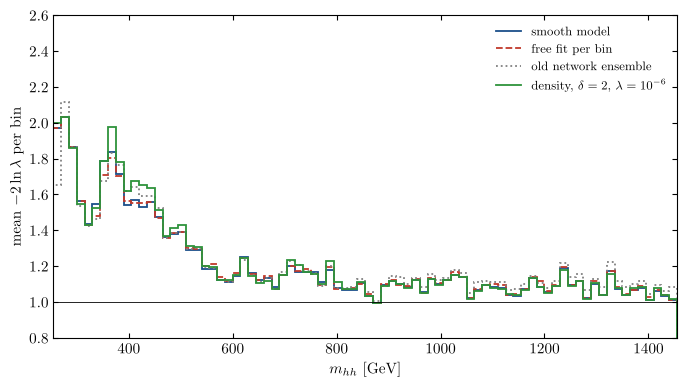

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
style = {'smooth model': ('#1B4F8A', '-'), 'free fit per bin': ('#C0392B', '--'),
         'old network ensemble': ('gray', ':'), LABEL[FEATURED]: ('#2E933C', '-')}
for name, (c, ls) in style.items():
    ax.stairs(np.nanmean(LR[name], 0), EDGES, color=c, ls=ls, lw=1.3, label=name)
ax.axhline(1, color='k', lw=0.6)
ax.set_xlim(255, 1455); ax.set_ylim(0.8, 2.6)
ax.set_xlabel(r'$m_{hh}$ [GeV]'); ax.set_ylabel(r'mean $-2\ln\lambda$ per bin')
ax.legend(frameon=False, fontsize=9)
fig.tight_layout(); fig.savefig(f'{FIGDIR}/fig_eval_accuracy.pdf'); plt.show()

## 2. Calibration: a model-error term for each model

The pull of bin $k$ of spectrum $s$ is
$$
z = \frac{t - f}{\sqrt{s^2_\text{noise} + s^2_\text{fit} + \delta^2}}, \qquad s^2_\text{noise} = q\,\max(f, q), \qquad \delta = \varepsilon(m)\,S, \quad S = \sum_i |C_i(\theta) A_{ik}| ,
$$
with $A_{ik}$ the integral of $a_i$ over bin $k$, **each model's own**. A single network has no fit uncertainty; we set $s_\text{fit} = 0$ for the networks until a seeds ensemble exists (the old ensembles put it at a few per cent of the noise).

$\varepsilon(m)$ is determined for each model exactly as for the smooth model: on the 38,076 quick-test rows, never used in training, solve $\langle (t-f)^2/(s^2_\text{noise} + s^2_\text{fit} + \varepsilon_k^2 S^2)\rangle = 1$ in each bin, then fit $\ln\varepsilon$ by a quadratic in $u = (m - 855)/600$, weighting each bin by the square root of its number of rows. As a check, the density network is also evaluated with the smooth model's $\varepsilon$.

In [7]:
C_q, b_q, t_q, q_q = quick_test_rows()
u_c = (CENTRES - 855) / 600
n_rows = np.bincount(b_q, minlength=80)

def fit_epsilon(f_q, v_q, S_q):
    # per-bin epsilon from <z^2> = 1 on the quick-test rows, then ln(eps) quadratic in u
    noise_q = q_q * np.maximum(f_q, q_q)
    e2 = np.zeros(80)
    for k in range(80):
        s = b_q == k; r2 = (t_q - f_q)[s]**2
        g = lambda c: np.mean(r2 / (noise_q[s] + v_q[s] + c * S_q[s]**2)) - 1
        e2[k] = 0.0 if g(0) <= 0 else brentq(g, 0, 1.0)
    ok = e2 > 0
    p = np.polyfit(u_c[ok], 0.5 * np.log(e2[ok]), 2, w=np.sqrt(n_rows[ok]))
    return np.exp(np.polyval(p, u_c)), np.sqrt(e2)

I_bins = smooth.basis.integrals(EDGES)
A_smooth = smooth.coefficient_integrals(I_bins)                  # [80, 23]
f_q_s, v_q_s = smooth.predict(C_q, I_bins[b_q])
eps_smooth, eps_smooth_bin = fit_epsilon(f_q_s, v_q_s, np.abs(C_q * A_smooth[b_q]).sum(1))
print('smooth model: epsilon (%) at 262.5, 600, 1447.5 GeV:', np.round(100 * eps_smooth[[0, 23, 79]], 3),
      ' (stored:', np.round(100 * eps[[0, 23, 79]], 3), ')')

EPS, EPS_BIN, A_NET = {}, {}, {}
for run, net in nets.items():
    with torch.no_grad():
        A = net.bin_integrals().numpy()                           # [80, 23] the network's A_ik
    A_NET[run] = A
    f_q = (C_q * A[b_q]).sum(1)
    EPS[run], EPS_BIN[run] = fit_epsilon(f_q, np.zeros_like(f_q), np.abs(C_q * A[b_q]).sum(1))
    print(f'{run:28s} epsilon (%) at 262.5, 600, 1447.5 GeV: {np.round(100 * EPS[run][[0, 23, 79]], 3)}')

smooth model: epsilon (%) at 262.5, 600, 1447.5 GeV: [0.077 0.279 3.687]  (stored: [0.077 0.279 3.687] )
DENS_L1_SiLU_thr             epsilon (%) at 262.5, 600, 1447.5 GeV: [0.101 0.403 4.558]
FTD_SiLU_huber_d1_pearson    epsilon (%) at 262.5, 600, 1447.5 GeV: [0.072 0.271 3.223]
FTD_SiLU_huber_d2_pearson    epsilon (%) at 262.5, 600, 1447.5 GeV: [0.07  0.279 2.819]


FTD_SiLU_huber_d3_pearson    epsilon (%) at 262.5, 600, 1447.5 GeV: [0.072 0.282 2.742]
FTD_SiLU_chi2_pearson        epsilon (%) at 262.5, 600, 1447.5 GeV: [0.074 0.285 2.827]
FTD_SiLU_huber_d2_pearson_curv1e-06 epsilon (%) at 262.5, 600, 1447.5 GeV: [0.07  0.275 2.887]
FTD_SiLU_huber_d2_pearson_curv1e-05 epsilon (%) at 262.5, 600, 1447.5 GeV: [0.073 0.281 2.865]
FTD_SiLU_huber_d2_pearson_curv0.0001 epsilon (%) at 262.5, 600, 1447.5 GeV: [0.091 0.293 2.965]


In [8]:
canc = T.sum(1) / S.sum(1)                                        # cancellation ratio (smooth model's S)
q5 = np.quantile(canc, [0, .2, .4, .6, .8, 1])
fifths = [(canc >= a_) & (canc <= b_) for a_, b_ in zip(q5[:-1], q5[1:])]
use = (T > 0) | (f > 0)

def pulls(fp, vp, Sp, e):
    noise_ = qt[:, None] * np.maximum(fp, qt[:, None])
    return np.where(use, (T - fp) / np.sqrt(noise_ + vp + (e[None] * Sp)**2), np.nan)

def summary(z_):
    return (np.nanstd(z_), np.nanstd(z_[:, :20]), np.nanstd(z_[:, 20:]), np.nanmean(np.abs(z_) < 2),
            [np.nanmean(z_[s]**2) for s in fifths])

rows_ = [('smooth model, own epsilon', pulls(f, v, S, eps_smooth)),
         ('smooth model, no model error', pulls(f, v, S, 0 * eps))]
Z = {}
for run in RUNS:
    S_net = np.abs(C_test[:, None, :] * A_NET[run][None]).sum(2)
    Z[run] = pulls(pred[LABEL[run]], 0.0, S_net, EPS[run])
    rows_.append((LABEL[run] + ', own epsilon', Z[run]))
    if run == FEATURED:
        rows_.append((LABEL[run] + ', smooth epsilon', pulls(pred[LABEL[run]], 0.0, S_net, eps_smooth)))
        rows_.append((LABEL[run] + ', no model error', pulls(pred[LABEL[run]], 0.0, S_net, 0 * eps)))

print(f'{"":44s} {"s.d.":>6s} {"<555":>6s} {">555":>6s} {"|z|<2":>6s}   <z^2> by cancellation fifth (1 = strongest)')
for name, z_ in rows_:
    a_, b_, c_, d_, e_ = summary(z_)
    print(f'{name.replace("$", "").replace(chr(92), ""):44s} {a_:6.3f} {b_:6.3f} {c_:6.3f} {d_:6.3f}   {np.round(e_, 2)}')

                                               s.d.   <555   >555  |z|<2   <z^2> by cancellation fifth (1 = strongest)
smooth model, own epsilon                     1.004  1.011  1.001  0.954   [0.97 0.98 1.04 1.04 1.  ]
smooth model, no model error                  1.090  1.218  1.043  0.939   [1.7  1.1  1.07 1.06 1.01]
density, L1 (start), own epsilon              1.020  1.079  0.999  0.954   [1.12 1.03 1.05 1.03 0.98]
density, Huber delta=1, own epsilon           1.007  1.014  1.005  0.954   [1.   0.99 1.03 1.04 1.  ]
density, Huber delta=2, own epsilon           1.007  1.015  1.004  0.954   [1.   0.99 1.04 1.04 1.  ]
density, Huber delta=3, own epsilon           1.007  1.015  1.004  0.954   [1.   1.   1.04 1.04 1.  ]
density, chi^2, own epsilon                   1.007  1.016  1.005  0.954   [1.   1.   1.04 1.04 1.  ]
density, delta=2, lambda=10^{-6}, own epsilon  1.007  1.015  1.005  0.954   [1.   0.99 1.04 1.04 1.  ]
density, delta=2, lambda=10^{-6}, smooth epsilon  1.003  1.008  

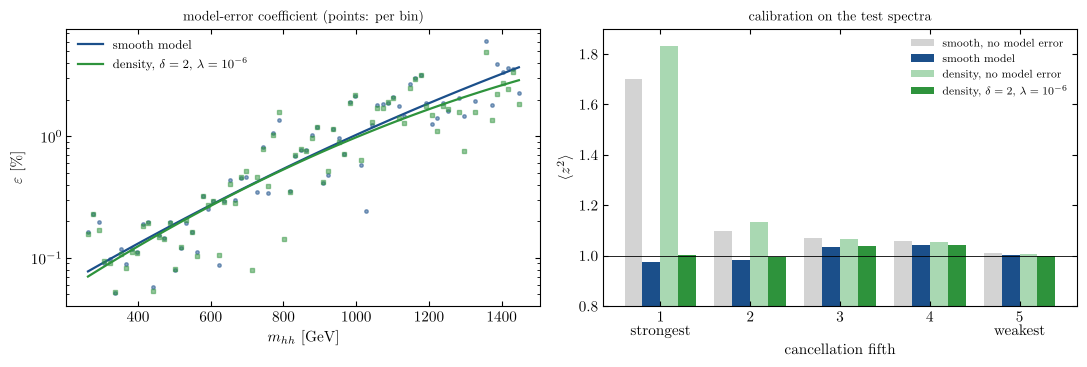

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ok = eps_smooth_bin > 0
ax[0].semilogy(CENTRES[ok], 100 * eps_smooth_bin[ok], 'o', ms=2.5, color='#1B4F8A', alpha=0.5)
ax[0].semilogy(CENTRES, 100 * eps_smooth, color='#1B4F8A', lw=1.6, label='smooth model')
ok = EPS_BIN[FEATURED] > 0
ax[0].semilogy(CENTRES[ok], 100 * EPS_BIN[FEATURED][ok], 's', ms=2.5, color='#2E933C', alpha=0.5)
ax[0].semilogy(CENTRES, 100 * EPS[FEATURED], color='#2E933C', lw=1.6, label=LABEL[FEATURED])
ax[0].set_xlabel(r'$m_{hh}$ [GeV]'); ax[0].set_ylabel(r'$\varepsilon$ [\%]'); ax[0].legend(frameon=False, fontsize=9)
ax[0].set_title(r'model-error coefficient (points: per bin)', fontsize=10)
x5 = np.arange(5); w5 = 0.2
for j, (name, z_, c) in enumerate([('smooth, no model error', rows_[1][1], 'lightgray'),
                                   ('smooth model', rows_[0][1], '#1B4F8A'),
                                   ('density, no model error', pulls(pred[LABEL[FEATURED]], 0.0, np.abs(C_test[:, None, :] * A_NET[FEATURED][None]).sum(2), 0 * eps), '#A9D8B2'),
                                   (LABEL[FEATURED], Z[FEATURED], '#2E933C')]):
    ax[1].bar(x5 + (j - 1.5) * w5, summary(z_)[4], w5, color=c, label=name)
ax[1].axhline(1, color='k', lw=0.6); ax[1].set_ylim(0.8, 1.9)
ax[1].set_xticks(x5); ax[1].set_xticklabels(['1\nstrongest', '2', '3', '4', '5\nweakest'])
ax[1].set_xlabel('cancellation fifth'); ax[1].set_ylabel(r'$\langle z^2\rangle$'); ax[1].legend(frameon=False, fontsize=8)
ax[1].set_title('calibration on the test spectra', fontsize=10)
fig.tight_layout(); fig.savefig(f'{FIGDIR}/fig_eval_calibration.pdf'); plt.show()

## 3. The density itself

The density network and the smooth model are both densities, so they can be compared at any $m_{hh}$, not just through bin integrals. On a 0.5 GeV grid from 255 to 1455 GeV, for the 1,000 test points:

* the relative difference $(\text{network} - \text{smooth})/\text{smooth}$, at the bin centres and between them;
* the difference in units of the smooth model's total uncertainty of the density, $\sqrt{s^2_\text{fit} + \delta^2}$ with $\delta = \varepsilon(m)\sum_i|C_i a_i(m)|$: the fraction within 1 and 2 standard deviations.

In [10]:
mg = np.arange(255.0, 1455.0 + 1e-9, 0.5)
on_c = np.isin(mg, CENTRES)
a_s, _ = smooth.coefficients(mg)                                  # [M, 23] smooth model's a_i(m)
dens_s, sd_s = smooth.dsigma_dm(theta, mg)                         # [1000, M] density and fit s.d.
eps_g = np.exp(np.polyval(np.polyfit(u_c, np.log(eps_smooth), 2), (mg - 855) / 600))
dS = np.zeros_like(dens_s)
for i0 in range(0, nS, 100):                                       # sum_i |C_i a_i(m)|, in chunks
    dS[i0:i0 + 100] = np.abs(C_test[i0:i0 + 100, None, :] * a_s[None]).sum(2)
sd_tot = np.sqrt(sd_s**2 + (eps_g[None] * dS)**2)

DENS = {run: nets[run].dsigma_dm(theta, mg) for run in RUNS}
print(f'{"run":28s} {"median |rel. diff| (%)":>24s} {"at centres":>11s} {"between":>8s} {"<1 sd":>7s} {"<2 sd":>7s}   (255-1455 GeV)')
for run in RUNS:
    rel = (DENS[run] - dens_s) / np.abs(dens_s)
    zz = (DENS[run] - dens_s) / sd_tot
    print(f'{run:28s} {100 * np.median(np.abs(rel)):24.3f} {100 * np.median(np.abs(rel[:, on_c])):11.3f} '
          f'{100 * np.median(np.abs(rel[:, ~on_c])):8.3f} {np.mean(np.abs(zz) < 1):7.3f} {np.mean(np.abs(zz) < 2):7.3f}')
low = mg <= 555
rel = (DENS[FEATURED] - dens_s) / np.abs(dens_s); zz = (DENS[FEATURED] - dens_s) / sd_tot
print(f'\n{FEATURED}, 255-555 GeV: median |rel. diff| {100 * np.median(np.abs(rel[:, low])):.3f}%, '
      f'within 1 sd {np.mean(np.abs(zz[:, low]) < 1):.3f}, within 2 sd {np.mean(np.abs(zz[:, low]) < 2):.3f}')

run                            median |rel. diff| (%)  at centres  between   <1 sd   <2 sd   (255-1455 GeV)
DENS_L1_SiLU_thr                                1.032       1.034    1.031   0.570   0.822
FTD_SiLU_huber_d1_pearson                       0.347       0.330    0.348   0.900   0.976


FTD_SiLU_huber_d2_pearson                       0.332       0.315    0.333   0.896   0.974
FTD_SiLU_huber_d3_pearson                       0.322       0.307    0.323   0.895   0.973
FTD_SiLU_chi2_pearson                           0.337       0.322    0.337   0.888   0.971


FTD_SiLU_huber_d2_pearson_curv1e-06                    0.314       0.297    0.315   0.902   0.976
FTD_SiLU_huber_d2_pearson_curv1e-05                    0.329       0.312    0.329   0.900   0.973
FTD_SiLU_huber_d2_pearson_curv0.0001                    0.381       0.368    0.381   0.866   0.953



FTD_SiLU_huber_d2_pearson_curv1e-06, 255-555 GeV: median |rel. diff| 0.190%, within 1 sd 0.828, within 2 sd 0.948


### Between bin centres: the three spectra of `fig_interpolation`

The old network ensemble (20 networks, bin values read as a density by dividing by 15 GeV), the smooth model with its fit and total bands, and the density networks, for the three test spectra of the paper figure. Lower panels: the spread of the 20 old networks, and the spread of the density networks (the four fine-tunes and the L1 start), relative to the density, against the smooth model's fit uncertainty.

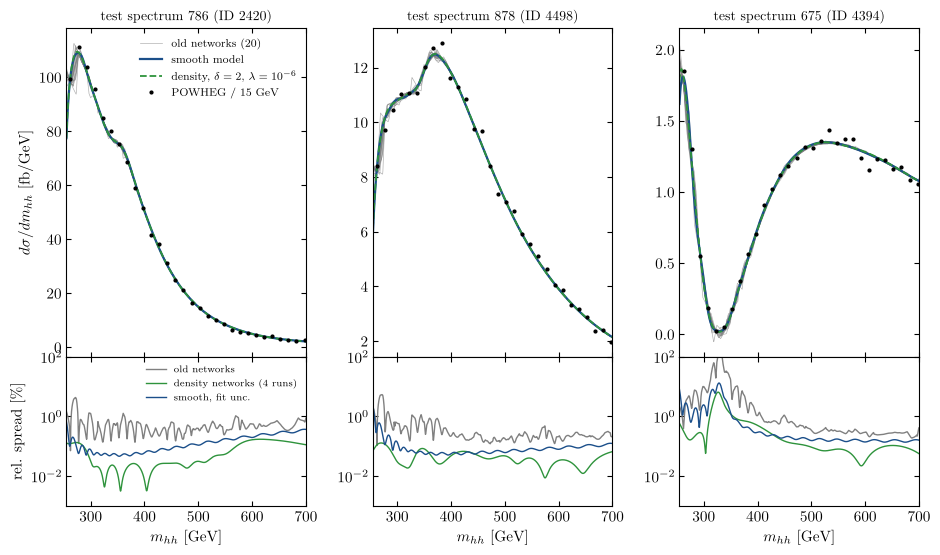

spectrum 786: max relative spread 255-600 GeV: old networks 4.28%, density runs 0.16%; max |featured - smooth| / smooth 0.62%
spectrum 878: max relative spread 255-600 GeV: old networks 5.36%, density runs 0.13%; max |featured - smooth| / smooth 2.42%
spectrum 675: max relative spread 255-600 GeV: old networks 176.89%, density runs 6.46%; max |featured - smooth| / smooth 20.15%


In [11]:
SPEC = [786, 878, 675]
mf = np.arange(255.0, 700.01, 0.5)
old = network_density(theta[SPEC], mf) / 15.0                       # [20, 3, M] pb/GeV
d_s, sd_f = smooth.dsigma_dm(theta[SPEC], mf)
dn = np.array([nets[run].dsigma_dm(theta[SPEC], mf) for run in SPREAD_RUNS])   # [runs, 3, M]
d_feat = nets[FEATURED].dsigma_dm(theta[SPEC], mf)
cen = CENTRES[CENTRES <= 700]
fig = plt.figure(figsize=(11, 6.2))
gs = fig.add_gridspec(2, 3, height_ratios=[2.2, 1], hspace=0.0, wspace=0.28)
for b, s in enumerate(SPEC):
    ax = fig.add_subplot(gs[0, b]); rx = fig.add_subplot(gs[1, b], sharex=ax)
    for a_ in range(len(old)):
        ax.plot(mf, 1e3 * old[a_, b], color='gray', lw=0.5, alpha=0.6, label='old networks (20)' if a_ == 0 else None)
    ax.plot(mf, 1e3 * d_s[b], color='#1B4F8A', lw=1.6, label='smooth model')
    ax.plot(mf, 1e3 * d_feat[b], color='#2E933C', lw=1.3, ls='--', label=LABEL[FEATURED])
    ax.plot(cen, 1e3 * T[s, :len(cen)] / 15.0, 'k.', ms=4, label='POWHEG / 15 GeV')
    ax.set_xlim(255, 700); ax.tick_params(labelbottom=False)
    ax.set_title(f'test spectrum {s} (ID {D["id"][s]})', fontsize=10)
    if b == 0:
        ax.set_ylabel(r'$d\sigma/dm_{hh}$ [fb/GeV]'); ax.legend(frameon=False, fontsize=8)
    rx.semilogy(mf, 100 * old[:, b].std(0) / np.abs(old[:, b].mean(0)), color='gray', lw=1, label='old networks')
    rx.semilogy(mf, 100 * dn[:, b].std(0) / np.abs(dn[:, b].mean(0)), color='#2E933C', lw=1, label=f'density networks ({len(SPREAD_RUNS)} runs)')
    rx.semilogy(mf, 100 * sd_f[b] / np.abs(d_s[b]), color='#1B4F8A', lw=1, label='smooth, fit unc.')
    rx.set_xlabel(r'$m_{hh}$ [GeV]'); rx.set_ylim(1e-3, 1e2)
    if b == 0:
        rx.set_ylabel(r'rel. spread [\%]'); rx.legend(frameon=False, fontsize=7)
fig.savefig(f'{FIGDIR}/fig_eval_interpolation.pdf', bbox_inches='tight'); plt.show()
for b, s in enumerate(SPEC):
    sel = mf <= 600
    print(f'spectrum {s}: max relative spread 255-600 GeV: old networks {100 * (old[:, b].std(0) / np.abs(old[:, b].mean(0)))[sel].max():.2f}%, '
          f'density runs {100 * (dn[:, b].std(0) / np.abs(dn[:, b].mean(0)))[sel].max():.2f}%; '
          f'max |featured - smooth| / smooth {100 * np.abs(d_feat[b] / d_s[b] - 1)[sel].max():.2f}%')

### The 23 coefficient functions

The density network's $a_i(m)$ (green) against the smooth model's, with its exact $\pm1\sigma$ band (blue), as $15\,\text{GeV}\times a_i$ in fb. The functions whose monomials are small or nearly degenerate over the sampled $\theta$ ($a_{16}$–$a_{20}$) are the least well determined, and may differ.

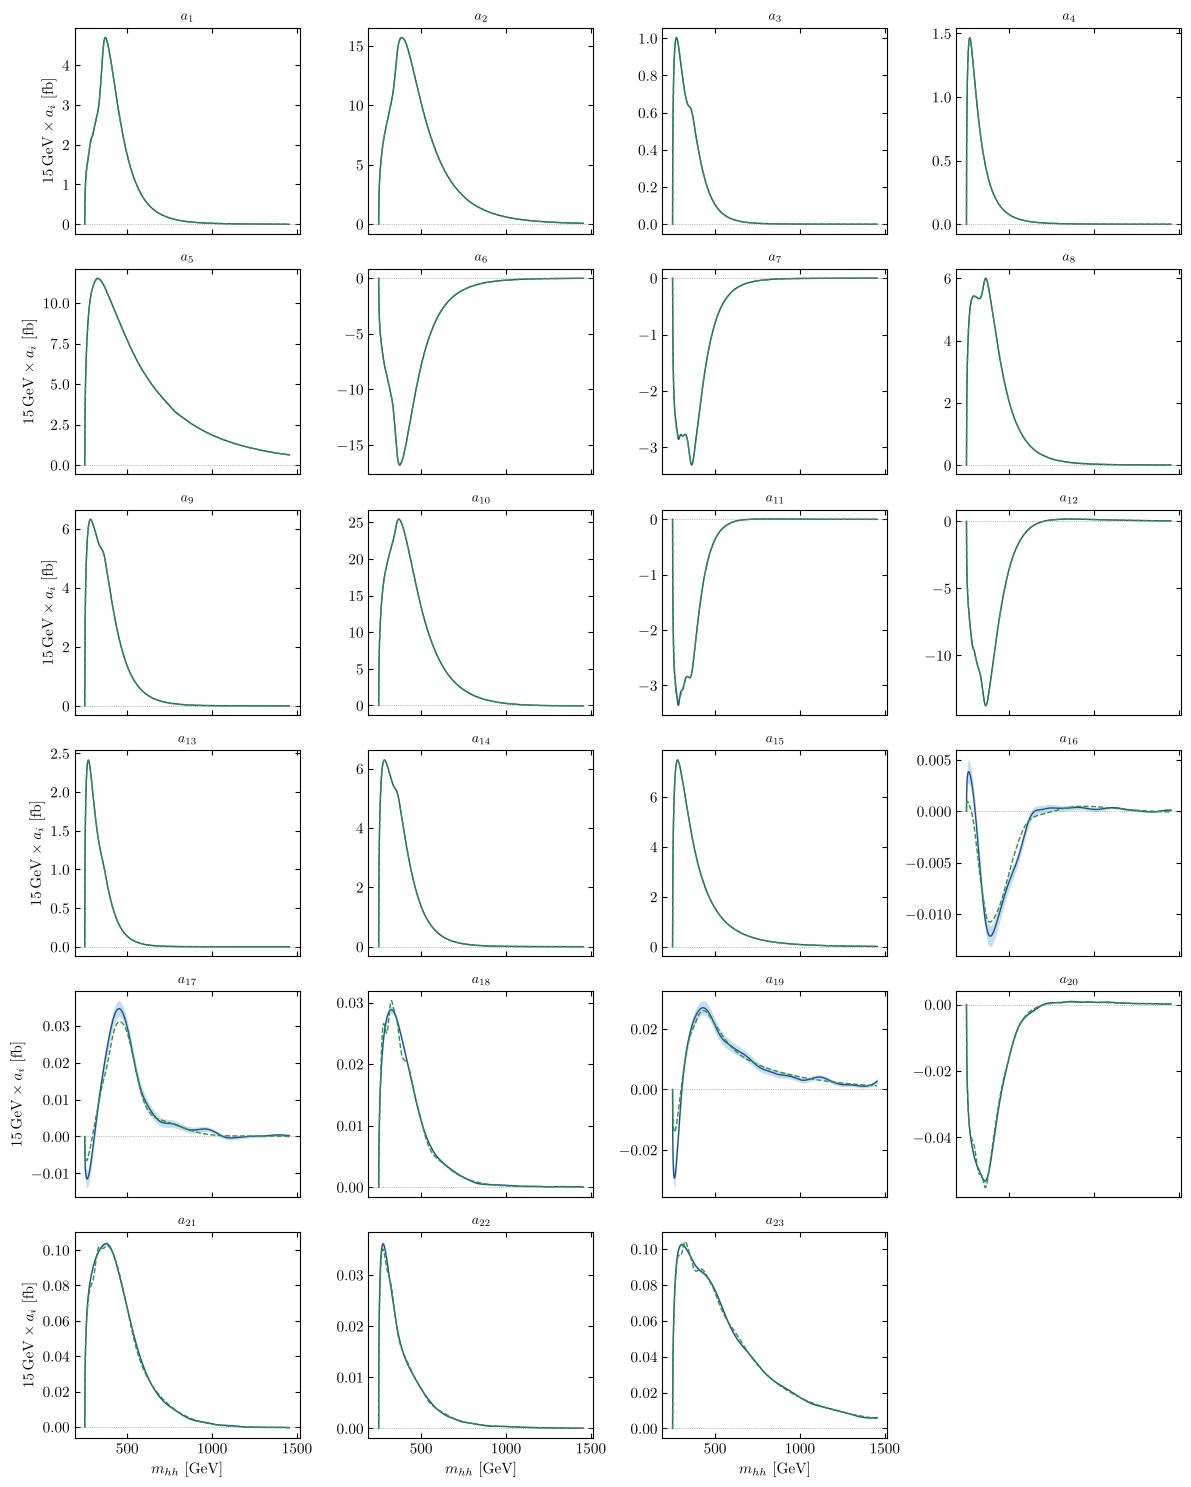

r.m.s. difference / max|a_i| (%), a_1 ... a_23:
[0.22 0.09 0.09 0.16 0.15 0.09 0.25 0.09 0.04 0.06 0.48 0.28 0.11 0.05
 0.04 6.66 5.05 2.23 8.09 1.13 1.26 0.96 1.21]
fraction of 250-1455 GeV within 2 fit-sigma of the smooth model:
[0.66 0.69 0.61 0.54 0.57 0.77 0.48 0.67 0.74 0.81 0.48 0.69 0.51 0.76
 0.87 0.92 0.92 0.88 0.97 0.96 0.92 0.85 0.88]


In [12]:
mc = np.arange(250.0, 1455.0 + 1e-9, 1.0)
a_sm, sd_sm = smooth.coefficients(mc)
a_nn = nets[FEATURED].coefficients(mc)
fig, axes = plt.subplots(6, 4, figsize=(12, 15), sharex=True)
for i, ax in enumerate(axes.flat[:23]):
    y, e_ = 15e3 * a_sm[:, i], 15e3 * sd_sm[:, i]
    ax.fill_between(mc, y - e_, y + e_, color='#C9DDF0', lw=0)
    ax.plot(mc, y, color='#1B4F8A', lw=1)
    ax.plot(mc, 15e3 * a_nn[:, i], color='#2E933C', lw=1, ls='--')
    ax.axhline(0, color='gray', lw=0.5, ls=':')
    ax.set_title(f'$a_{{{i + 1}}}$', fontsize=10)
axes.flat[23].axis('off')
for ax in axes[:, 0]:
    ax.set_ylabel(r'$15\,\mathrm{GeV}\times a_i$ [fb]')
for ax in axes[-1]:
    ax.set_xlabel(r'$m_{hh}$ [GeV]')
fig.tight_layout(); fig.savefig(f'{FIGDIR}/fig_eval_coefficients.pdf'); plt.show()

# agreement, per function: (1) the r.m.s. difference relative to the size of the
# function, max |a_i|; (2) the fraction of the grid within 2 sigma of the smooth
# model, where sigma is its FIT uncertainty only (very small, a few per cent of
# the POWHEG noise), so (2) is a severe test
rel_rms = np.sqrt(np.mean((a_nn - a_sm)**2, axis=0)) / np.abs(a_sm).max(0)
within = np.mean(np.abs(a_nn - a_sm) <= 2 * sd_sm, axis=0)
print('r.m.s. difference / max|a_i| (%), a_1 ... a_23:')
print(np.round(100 * rel_rms, 2))
print('fraction of 250-1455 GeV within 2 fit-sigma of the smooth model:')
print(np.round(within, 2))

### Smoothness of the coefficient functions

The relative curvature of each function's smooth part, $R_i = \sum_j (g_i''(z_j))^2 / \sum_j g_i(z_j)^2$ with $g_i = a_i/\phi$, in the network's input $z = 2\sqrt{(m-250)/1205} - 1$ (the quantity penalised by `HEFTDensity.curvature_penalty`, before averaging over $i$), for each run and for the smooth model; and the r.m.s. difference from the smooth model's $a_i$ relative to $\max|a_i|$. The wiggles of the unpenalised network are in $a_{16}$–$a_{19}$.

In [13]:
zc = torch.linspace(float(2 * np.sqrt(5 / 1205) - 1), 1.0, 1201, dtype=torch.float64)
hz = float(zc[1] - zc[0])
def rel_curvature(g):
    d2 = (g[2:] - 2 * g[1:-1] + g[:-2]) / hz**2
    return (d2**2).sum(0) / (g**2).sum(0)
mz = 250 + 1205 * ((zc.numpy() + 1) / 2)**2                     # the masses of the z grid
phi_z = np.sqrt(np.clip(1 - 4 * 125.0**2 / mz**2, 1e-12, None))
a_sz = smooth.coefficients(mz)[0]
R_smooth = rel_curvature(a_sz / phi_z[:, None])
groups = {'a1-a15': slice(0, 15), 'a16-a19': slice(15, 19), 'a20-a23': slice(19, 23)}
print(f'{"":40s} {"median R":>9s} {"R, a16-a19":>36s} {"rms diff / max|a| (%)":>28s}')
print(f'{"":40s} {"a1-a15":>9s} {"":>36s} {"a1-a15":>9s} {"a16-a19":>9s} {"a20-a23":>9s}')
print(f'{"smooth model":40s} {np.median(R_smooth[:15]):9.0f} {np.array2string(R_smooth[15:19], precision=0, floatmode="fixed"):>36s}')
for run in RUNS:
    with torch.no_grad():
        Rn = rel_curvature(nets[run].coeffs(zc)).numpy()
    a_r = nets[run].coefficients(mz)
    rr = np.sqrt(np.mean((a_r - a_sz)**2, 0)) / np.abs(a_sz).max(0)
    print(f'{run:40s} {np.median(Rn[:15]):9.0f} {np.array2string(Rn[15:19], precision=0, floatmode="fixed"):>36s} '
          f'{100 * np.median(rr[:15]):9.2f} {100 * np.median(rr[15:19]):9.2f} {100 * np.median(rr[19:]):9.2f}')

                                          median R                           R, a16-a19        rms diff / max|a| (%)
                                            a1-a15                                         a1-a15   a16-a19   a20-a23
smooth model                                   134                [960. 583.  16. 426.]
DENS_L1_SiLU_thr                               152    [ 36078. 225649.  15889.   7017.]      0.47     48.86      6.73
FTD_SiLU_huber_d1_pearson                      141    [273637. 187644.   6558.   8531.]      0.18     14.69      2.70
FTD_SiLU_huber_d2_pearson                      141    [288851. 170242.   6219.   4791.]      0.14     12.82      2.42
FTD_SiLU_huber_d3_pearson                      141    [290869. 160441.   6620.   3851.]      0.13     10.95      2.34
FTD_SiLU_chi2_pearson                          142    [404807. 198744.   8190.   5082.]      0.13     15.24      2.66
FTD_SiLU_huber_d2_pearson_curv1e-06            136            [1270. 1026. 1557.  319.]

## 4. Below the fitted range: the bin 240–255 GeV

Both models carry the threshold factor $\phi(m) = \sqrt{1 - 4m_h^2/m^2}$, which vanishes at 250 GeV, so their prediction for the POWHEG bin 240–255 GeV is the integral of the density over 250–255 GeV. This bin was never used in training. POWHEG's value is in the source file (`data/powheg_total_gauss_params_13TeV.csv.gz`, column `16`), whose rows are matched to the test spectra by their `ID`.

In [14]:
src = pd.read_csv('../data/powheg_total_gauss_params_13TeV.csv.gz')
id_col = src.columns[-1]                                          # the last column holds the ID
t16 = src.set_index(id_col).loc[D['id'], '16'].to_numpy(np.float64)   # POWHEG, 240-255 GeV (pb)
n16 = np.rint(t16 / qt)                                           # its count

from dihiggs.quadrature import bin_nodes
m_e, w_e = bin_nodes([250.0, 255.0], 16)                          # 16 Gauss-Legendre nodes on 250-255 GeV
f16 = {'smooth model': smooth.spectrum(theta, edges=[250.0, 255.0], discrepancy=False)[0][:, 0]}
for run in [RUNS[0], FEATURED]:
    with torch.no_grad():
        a_e = nets[run].density_coeffs(m_e.double()).numpy()       # [16, 23]
    f16[LABEL[run]] = C_test @ (w_e.numpy()[:, None] * a_e).sum(0)
print(f'POWHEG events in 240-255 GeV, all 1,000 spectra: {int(n16.sum())}')
for name, fp in f16.items():
    print(f'{name.replace("$", "").replace(chr(92), ""):28s} observed / predicted (sum over spectra) = {t16.sum() / fp.sum():.3f}; '
          f'median of per-spectrum ratio = {np.median(t16[fp > 0] / fp[fp > 0]):.3f}')

POWHEG events in 240-255 GeV, all 1,000 spectra: 316626
smooth model                 observed / predicted (sum over spectra) = 0.937; median of per-spectrum ratio = 0.957
density, L1 (start)          observed / predicted (sum over spectra) = 0.927; median of per-spectrum ratio = 0.926
density, delta=2, lambda=10^{-6} observed / predicted (sum over spectra) = 0.936; median of per-spectrum ratio = 0.917


## Summary

See `docs/density/density_results.pdf` for the write-up of these results.